# M2 — Pipeline de detecção de arranhões (demonstração)

Executa o pipeline da M2 de ponta a ponta e reproduz o experimento **A (baseline M1) × B (proposta M2)**.

**Pré-requisitos:** `pip install -r requirements.txt` e o dataset preparado em `data/car_scratch/`
(ver `docs/relatorio_m2.md`, seção 3.1, e `scripts/preparar_dados.py`).

Rode em ordem a partir de um kernel reiniciado (*Kernel → Restart & Run All*). Tempo total ≈ 2 min.

In [1]:
import os, sys, json, csv
from pathlib import Path

# o notebook fica em notebooks/; trabalha a partir da raiz do repositório
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

import cv2
import numpy as np
import matplotlib.pyplot as plt
import yaml

from src.data import carregar, ler_imagem
from src.pipeline import processar
from src.avaliacao import avaliar_imagem
from src.executar import executar

DADOS = Path("data/car_scratch")
assert (DADOS / "_annotations.coco.json").exists(), "Dataset não preparado: rode scripts/preparar_dados.py"
print("raiz:", RAIZ)

raiz: C:\Users\MateusRachadelLohn\projeto-vistoria-veiculos


## 1. Dados

67 fotos próximas da lataria (`IMG_5481`–`IMG_5667`) do dataset *Car scratch* v10 (CC BY 4.0), com polígonos de arranhão.
Divisão pela ordem de captura: 13 imagens de **ajuste** (escolha de parâmetros) e 54 de **teste** (avaliação final).

In [2]:
catalogo = list(csv.DictReader(open("data/catalogo.csv", encoding="utf-8")))
for conj in ("ajuste", "teste"):
    linhas = [l for l in catalogo if l["conjunto"] == conj]
    print(f"{conj:6s}: {len(linhas):2d} imagens, {sum(int(l['n_arranhoes']) for l in linhas)} arranhões anotados "
          f"({sum(int(l['n_tiny']) for l in linhas)} tiny-scratch)")
print()
print("primeiras linhas do catálogo:")
for l in catalogo[:3]:
    print(l)

ajuste: 13 imagens, 178 arranhões anotados (122 tiny-scratch)
teste : 54 imagens, 743 arranhões anotados (358 tiny-scratch)

primeiras linhas do catálogo:
{'id': 'IMG_5481', 'numero': '5481', 'conjunto': 'ajuste', 'largura': '1280', 'altura': '960', 'n_arranhoes': '8', 'n_tiny': '6', 'brilho_medio': '152.8', 'saturacao_media': '27.8', 'frac_reflexo': '0.0419', 'frac_area_anotada': '0.0005'}
{'id': 'IMG_5482', 'numero': '5482', 'conjunto': 'ajuste', 'largura': '1280', 'altura': '961', 'n_arranhoes': '6', 'n_tiny': '1', 'brilho_medio': '148.7', 'saturacao_media': '18.8', 'frac_reflexo': '0.0214', 'frac_area_anotada': '0.0023'}
{'id': 'IMG_5483', 'numero': '5483', 'conjunto': 'ajuste', 'largura': '1280', 'altura': '960', 'n_arranhoes': '6', 'n_tiny': '0', 'brilho_medio': '146.9', 'saturacao_media': '18.6', 'frac_reflexo': '0.0319', 'frac_area_anotada': '0.0094'}


## 2. Configurações comparadas

- **A** reproduz a M1: Canny → dilatação → componentes com área ≥ 150 px².
- **B** é a proposta da M2, com parâmetros escolhidos por busca em grade **só no conjunto de ajuste** (`scripts/ajustar_parametros.py`).

In [3]:
cfgs = {n: yaml.safe_load(open(f"configs/{n}.yaml", encoding="utf-8")) for n in ("A_baseline_m1", "B_ajustado")}
print(yaml.safe_dump(cfgs["B_ajustado"], sort_keys=False, allow_unicode=True))

nome: B_ajustado
lado_max: 640
blur_ksize: 3
clahe: true
metodo: tophat
tophat_kernel: 9
limiar: p98
reflexo:
  v_min: 230
  s_max: 40
  dilatar: 7
  remover_antes: true
morfologia:
- op: abrir
  kernel: 2
  iter: 1
  forma: quadrado
- op: fechar
  kernel: 5
  iter: 1
  forma: elipse
filtros:
  area_min: 15
  area_max_frac: 0.05
  alongamento_min: 2.5
  frac_reflexo_max: 0.3
  textura_entorno_max: 20
  juncao_comp_frac: 0.15



## 3. Uma imagem passo a passo

Entrada → realce (top-hat + black-hat) → segmentação (percentil 98) → máscara de reflexo (HSV) → morfologia → componentes conexos → regiões aprovadas pela regra → comparação com a referência.

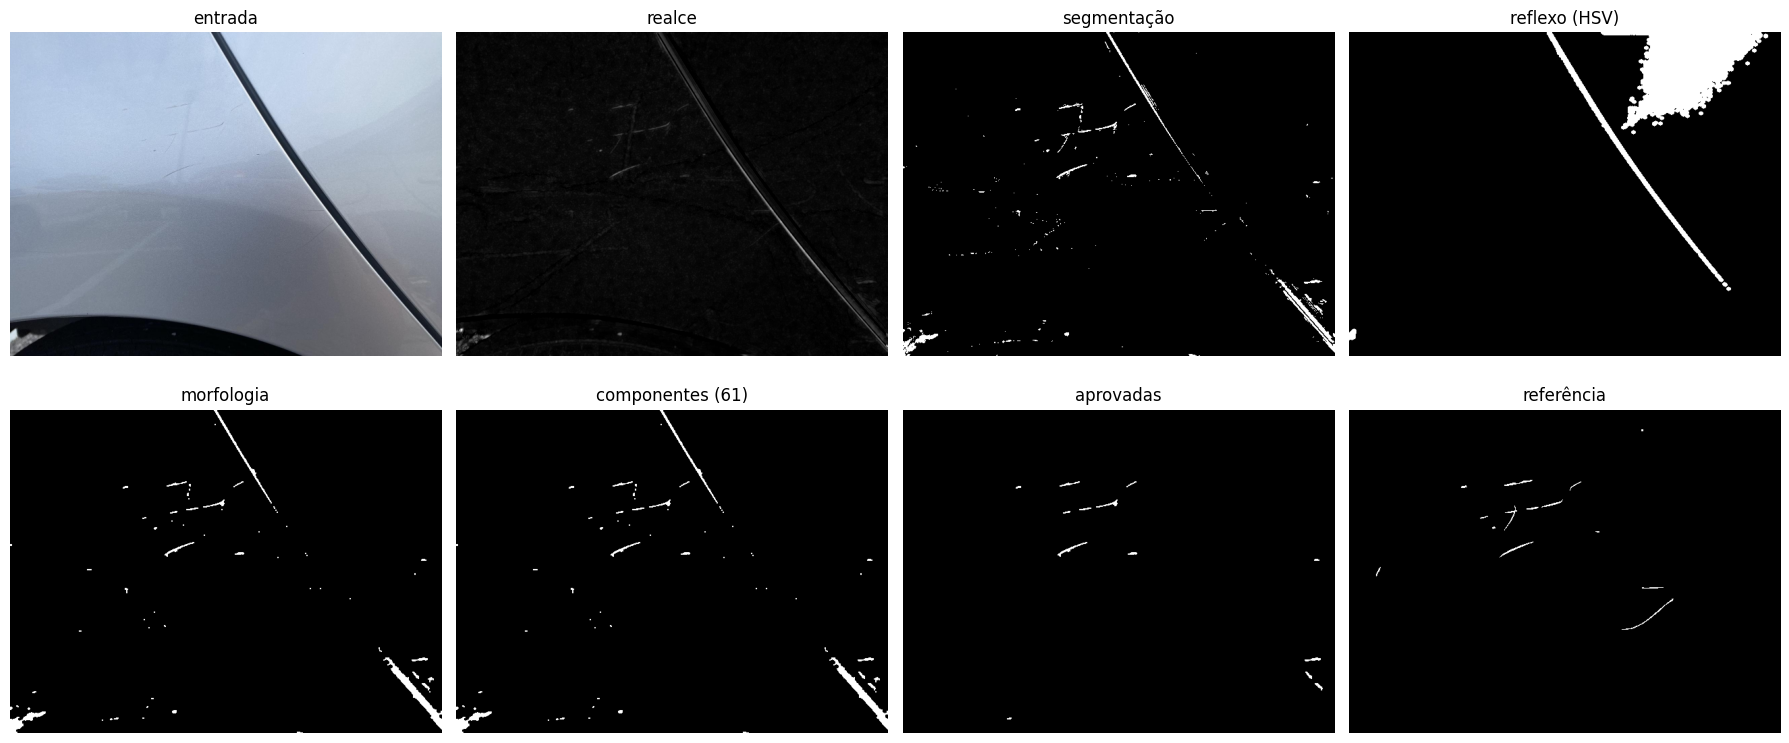

{'iou': 0.22212837837837837, 'dice': 0.36351071181755357, 'n_ref': 15, 'detectadas': 7, 'n_pred': 13, 'vp': 7, 'fp': 6}


In [4]:
amostras = {a.id: a for a in carregar(DADOS)}
a = amostras["IMG_5498"]
r = processar(ler_imagem(a.caminho), cfgs["B_ajustado"])
h, w = r["predicao"].shape
ref = np.zeros((h, w), np.uint8)
for m in a.instancias:
    ref |= cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST)

etapas = [(cv2.cvtColor(r["img"], cv2.COLOR_BGR2RGB), "entrada"), (r["realce"], "realce"),
          (r["binaria"], "segmentação"), (r["reflexo"], "reflexo (HSV)"), (r["morfologia"], "morfologia"),
          (r["rotulos"] > 0, f"componentes ({r['rotulos'].max()})"), (r["predicao"], "aprovadas"), (ref, "referência")]
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
for eixo, (im, t) in zip(ax.ravel(), etapas):
    eixo.imshow(im, cmap=None if np.ndim(im) == 3 else "gray"); eixo.set_title(t); eixo.axis("off")
plt.tight_layout(); plt.show()
print(avaliar_imagem(r["predicao"], [cv2.resize(m, (w, h), interpolation=cv2.INTER_NEAREST) for m in a.instancias]))

## 4. Descritores das regiões (representação e descrição)

Cada componente conexo recebe descritores de forma, intensidade, textura do entorno e cor (unidades e cálculo em `src/descritores.py`).
A regra de decisão aprova ou rejeita cada região e registra o motivo.

In [5]:
campos = ["rotulo", "area_px", "alongamento", "excentricidade", "solidez", "comprimento_frac",
          "contraste_local", "textura_entorno", "saturacao_media", "frac_reflexo", "aprovada", "motivo"]
regioes = sorted(r["descritores"], key=lambda d: -d["area_px"])[:12]
print(" | ".join(campos))
for d in regioes:
    print(" | ".join(str(d[c]) for c in campos))

rotulo | area_px | alongamento | excentricidade | solidez | comprimento_frac | contraste_local | textura_entorno | saturacao_media | frac_reflexo | aprovada | motivo
43 | 1262 | 11.1 | 0.996 | 0.656 | 0.18 | 34.1 | 50.2 | 63.0 | 0.011 | False | entorno texturizado
56 | 578 | 3.69 | 0.963 | 0.657 | 0.081 | 73.0 | 65.0 | 12.8 | 0.0 | False | entorno texturizado
1 | 539 | 40.98 | 1.0 | 0.59 | 0.228 | 66.0 | 74.3 | 99.8 | 0.0 | False | entorno texturizado
24 | 146 | 10.54 | 0.995 | 0.573 | 0.066 | 8.9 | 16.0 | 52.1 | 0.0 | True | arranhao
10 | 102 | 6.06 | 0.986 | 0.515 | 0.049 | 4.6 | 12.8 | 47.5 | 0.0 | True | arranhao
44 | 78 | 6.35 | 0.988 | 0.743 | 0.034 | 19.3 | 8.8 | 10.9 | 0.0 | True | arranhao
3 | 72 | 10.72 | 0.996 | 0.661 | 0.042 | 10.9 | 11.9 | 48.6 | 0.0 | True | arranhao
47 | 53 | 3.44 | 0.957 | 0.841 | 0.02 | 17.2 | 15.9 | 9.0 | 0.0 | True | arranhao
45 | 46 | 3.63 | 0.961 | 0.852 | 0.019 | 18.6 | 15.4 | 9.2 | 0.0 | True | arranhao
26 | 45 | 3.65 | 0.962 | 0.938 | 0.018 | 15

## 5. Experimento A × B no conjunto de teste

Mesmas 54 imagens, mesma referência e mesmas métricas; muda apenas o pipeline.

In [6]:
resumos = {}
for nome, cfg in cfgs.items():
    resumos[nome], _ = executar(cfg, DADOS, "teste", f"results/teste/{nome}")

chaves = ["precisao", "recall", "f1", "iou_medio", "dice_medio", "regioes_preditas", "fp_por_imagem"]
print(f"{'config':15s} " + " ".join(f"{k:>16s}" for k in chaves))
for nome, res in resumos.items():
    print(f"{nome:15s} " + " ".join(f"{res[k]:16.3f}" if isinstance(res[k], float) else f"{res[k]:16d}" for k in chaves))

config                  precisao           recall               f1        iou_medio       dice_medio regioes_preditas    fp_por_imagem
A_baseline_m1              0.071            0.287            0.114            0.011            0.022              494            8.500
B_ajustado                 0.170            0.030            0.050            0.017            0.027              100            1.537


**Leitura:** B reduz os falsos positivos por imagem de ≈ 8,5 para ≈ 1,5 e dobra a precisão, mas o recall cai de ≈ 0,29 para ≈ 0,03.
As regras de reflexo e de junção removem regiões sem perder arranhões reais; a perda de recall vem da fragmentação dos traços na segmentação.
Análise completa: `results/teste/analise.md` e `docs/relatorio_m2.md`, seção 6.

In [7]:
import subprocess
print(subprocess.run([sys.executable, "scripts/analisar_resultados.py"], capture_output=True, text=True).stdout)

# Analise do experimento no conjunto de teste

## 1. Resumo

| config | imagens | precisao | recall | F1 | IoU medio | Dice medio | regioes preditas | FP/imagem |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| A_baseline_m1 | 54 | 0.071 | 0.287 | 0.114 | 0.011 | 0.022 | 494 | 8.50 |
| B_ajustado | 54 | 0.170 | 0.030 | 0.050 | 0.017 | 0.027 | 100 | 1.54 |

## 2. Recall por tipo de anotacao

| config | tipo | detectadas | total | recall |
|---|---|---:|---:|---:|
| A_baseline_m1 | scratch | 132 | 385 | 0.343 |
| A_baseline_m1 | tiny-scratch | 81 | 357 | 0.227 |
| B_ajustado | scratch | 21 | 385 | 0.055 |
| B_ajustado | tiny-scratch | 1 | 357 | 0.003 |

## 3. Regioes candidatas por motivo de decisao

Pureza >= 0.5 = regiao sobre arranhao real. Para regras de rejeicao, 'reais' sao arranhoes perdidos pela regra.

| config | motivo | regioes | reais | % reais |
|---|---|---:|---:|---:|
| A_baseline_m1 | arranhao | 494 | 35 | 7.1 |
| A_baseline_m1 | area pequena | 34 | 4 | 11.8 |
| B_ajustad

## 6. Casos de sucesso e de falha (configuração B)

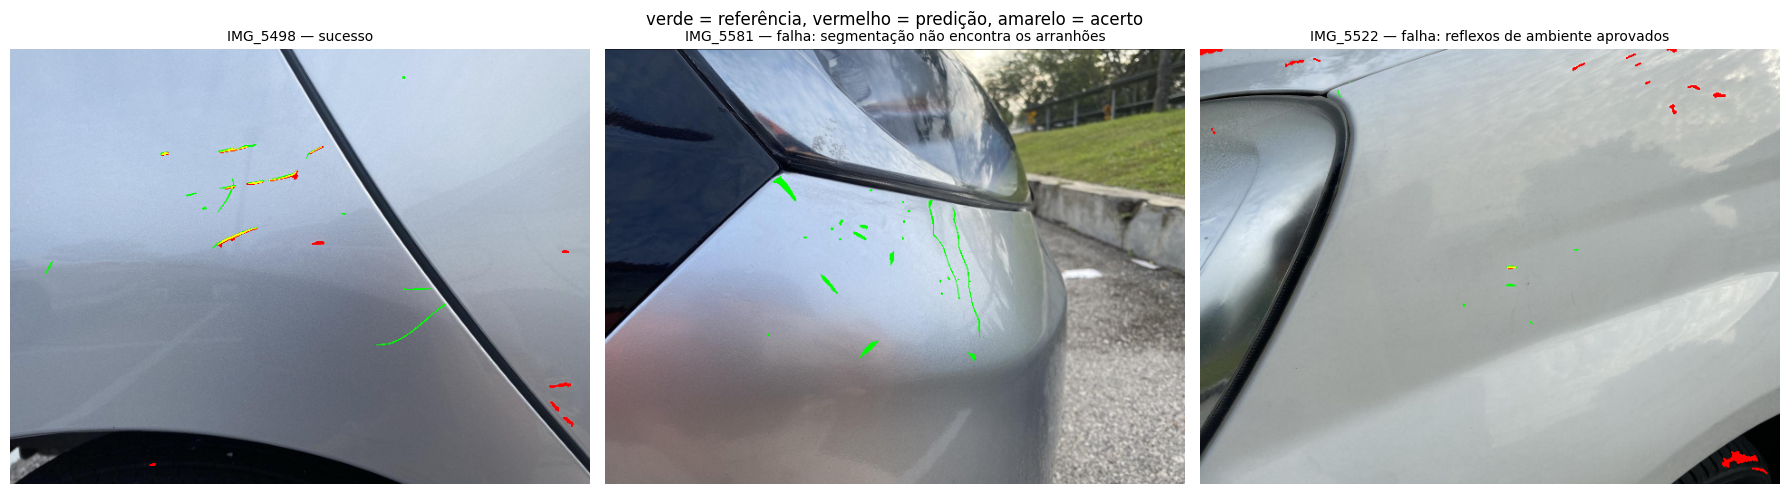

In [8]:
casos = {"IMG_5498": "sucesso", "IMG_5581": "falha: segmentação não encontra os arranhões",
         "IMG_5522": "falha: reflexos de ambiente aprovados"}
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for eixo, (i, desc) in zip(ax, casos.items()):
    am = amostras[i]
    rr = processar(ler_imagem(am.caminho), cfgs["B_ajustado"])
    hh, ww = rr["predicao"].shape
    rf = np.zeros((hh, ww), np.uint8)
    for m in am.instancias:
        rf |= cv2.resize(m, (ww, hh), interpolation=cv2.INTER_NEAREST)
    vis = cv2.cvtColor(rr["img"], cv2.COLOR_BGR2RGB)
    vis[rf == 1] = (0, 255, 0); vis[rr["predicao"] == 1] = (255, 0, 0); vis[(rf & rr["predicao"]) == 1] = (255, 255, 0)
    eixo.imshow(vis); eixo.set_title(f"{i} — {desc}", fontsize=10); eixo.axis("off")
plt.suptitle("verde = referência, vermelho = predição, amarelo = acerto")
plt.tight_layout(); plt.show()